# Transmit-corrected variable-flip-angle T1 imaging


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`measurements`，shape `(1, 128, 128, 2)`，dtype `<f8`：Scanner signal in arbitrary units, axes batch,x,y,flip-angle; original singleton slice removed；`b1_map`，shape `(1, 128, 128)`，dtype `<f8`：Independent transmit calibration B1, actual/nominal flip-angle ratio, dimensionless；`tissue_mask`，shape `(1, 128, 128)`，dtype `|u1`：Supplied brain support, dimensionless, 1 for fitted pixels。未知量为128×128脑T1(ms)和M0幅度图。

获取模型：已知独立B1修正flip角后SPGR稳态信号由T1和M0生成双flip角强度。

如何恢复：src.solvers.reconstruct/physics_model.linearized_fit：直接线性化斜率估计E并取log恢复T1。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell6主动恢复；8参考图；9观测/B1/支持；10信号解释；11不修正B1对照。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留4个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。B1是独立发送场校准，不是T1真值。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer longitudinal relaxation time T1 and equilibrium signal scale M0 from two real variable-flip-angle MR observations. Independent transmit calibration changes the actual flip angle and therefore the inferred relaxation.

The full original human brain slice is reconstructed at 4668 voxels in the supplied acquisition support. Independent transmit calibration changes the actual excitation angle.

This notebook actively reconstructs the bundled observations. The reproduced upstream result is a method reference, not physical ground truth. No historical paper metric is presented as a measurement from this run.


## 2. Data

The complete original 128 by 128 brain slice is fitted at 4668 supported voxels. Nominal angles are 3 and 20 degrees and repetition time 15 ms. B1 is independent dimensionless calibration; T1 is ms and M0 scanner arbitrary units, not calibrated proton density.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| measurements | (1, 128, 128, 2) | float64 | Scanner signal in arbitrary units, axes batch,x,y,flip-angle; original singleton slice removed |
| b1_map | (1, 128, 128) | float64 | Independent transmit calibration B1, actual/nominal flip-angle ratio, dimensionless |
| tissue_mask | (1, 128, 128) | uint8 | Supplied brain support, dimensionless, 1 for fitted pixels |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Nominal flip angles | 3, 20 | degrees | Last measurement axis in this order |
| Repetition time | 15 | ms | Equal at both flip angles |
| Voxel spacing x, y | 2, 2 | mm | Original NIfTI in-plane grid |
| Stored slice spacing | 1.9999983310699463 | mm | Original NIfTI header value; only one slice is supplied |
| Spatial axes | x, y | index | Original stored array orientation, no image rotation |
| Actual flip angle | B1 times nominal angle | degrees | Multiplicative transmit calibration convention |
| Support | Original supplied brain mask | dimensionless | 4,668 pixels; outside-support output is zero |
| Boundary | Independent voxel model | dimensionless | No spatial boundary coupling |
| Noise | Unknown scanner magnitude noise | arbitrary units | No variance estimate is supplied |

The observations are the qMRLab human brain VFA example, version 3. Original signal values and calibration values are preserved through NIfTI decoding into float64. Scanner field strength, echo time and an absolute proton-density scale are not documented in this example; they are not needed for the declared steady-state two-angle model, and M0 remains in arbitrary units.


## 3. Physics

The spoiled steady-state signal is $S=M_0\sin(a)(1-E)/(1-E\cos(a))$, $E=\exp(-TR/T_1)$ and $a=B_1\alpha\pi/180$. Here $\alpha$ is nominal degrees, $B_1$ transmit scale, $TR$ repetition time, $M_0$ equilibrium scale and $S$ observed signal. The model assumes effective spoiling and steady state.

The data contain an entire human brain slice at two flip angles, an independent normalized transmit-field map and its supplied brain support. Assume spoiled steady-state gradient echo magnitude signal


$$
S_j=M_0\sin(a_j)\frac{1-E}{1-E\cos(a_j)},\qquad
E=\exp(-TR/T_1),\qquad a_j=B_1\alpha_j\pi/180.
$$


Here j indexes measurements; S is measured signal in scanner arbitrary units, M0 is equilibrium magnetization in the same units, T1 is longitudinal relaxation time, TR is repetition time, alpha is nominal angle in degrees, B1 is the dimensionless independently measured transmit correction and a is actual angle in radians. Recover T1 and M0 at every supported pixel. Two measurements weakly constrain relaxation in the presence of measurement noise, and ignoring B1 produces spatially varying systematic bias. This model assumes effective spoiling and steady state; no unmeasured off-resonance or imperfect-spoiling correction is supplied.

### Physics and method

For each measured angle, S=M0 sin(a)(1-E)/(1-E cos(a)), E=exp(-TR/T1), a=B1 times nominal angle in radians. TR=15 ms; nominal angles are 3 and 20 degrees. Linearized coordinates y=S/sin(a), x=S/tan(a) satisfy y=E x+M0(1-E). Centered ordinary least squares yields E and its intercept, and T1=-TR/log(E).


## 4. Method

The local direct estimator forms $y=S/\sin(a)$ and $x=S/\tan(a)$, then centered ordinary least squares in $y=Ex+c$ gives $T_1=-TR/\log E$ and $M_0=c/(1-E)$. Zero outside the supplied support is the output convention, not inferred tissue relaxation.

Use the calibrated actual angles to linearize the spoiled gradient echo relation. With x=S/tan(a) and y=S/sin(a), the signal satisfies y=E x+M0(1−E). A linear fit estimates E and its intercept; invert the exponential for T1 and recover M0. Comparing with an assumed uniform transmit field helps expose the role of the independent calibration.


## 5. Results

The preserved cells actively compute calibrated outputs, compare with independently reproduced method maps, inspect signal predictions and run a fresh unit-B1 control. The loaded metrics ledger is a separate provenance check, not a replacement for the active fit.


In [1]:
from pathlib import Path
import sys,time,json,numpy as np
from matplotlib import pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
if not (ROOT/'src').exists(): raise RuntimeError('Execute from task or notebooks directory')
sys.path.insert(0,str(ROOT))
from src.solvers import reconstruct
from src.visualization import comparison,metrics
started=time.perf_counter()
fresh=reconstruct(ROOT/'data/raw_data.npz')
runtime=time.perf_counter()-started
reference=dict(np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False))
print('Fresh local reconstruction CPU wall seconds:',runtime)
for key,value in fresh.items(): print(key,value.shape,value.dtype,metrics(value,reference[key]))
print('Kernel:',sys.executable,'NumPy:',np.__version__)

Fresh local reconstruction CPU wall seconds: 0.002790499944239855
reconstruction (1, 128, 128) float64 (1.0000000000000002, 5.7137273510922145e-15)
equilibrium_magnetization (1, 128, 128) float64 (1.0000000000000002, 7.906641473030397e-15)
Kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6


In [2]:
import hashlib
ledger=json.loads((ROOT/'notebooks/reference_outputs/fresh_metrics.json').read_text(encoding='utf-8'))
assert ledger['observation_sha256']==hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
print('Measurement ledger:',ledger['kind'])
for key in fresh:
 n,e=metrics(fresh[key],reference[key])
 assert abs(e-ledger['judge_report']['metrics'][key+'_nrmse'])<1e-12
print('Fresh measurement ledger matches this active reconstruction.')

Measurement ledger: fresh cleaned-code measurement, not historical report
Fresh measurement ledger matches this active reconstruction.


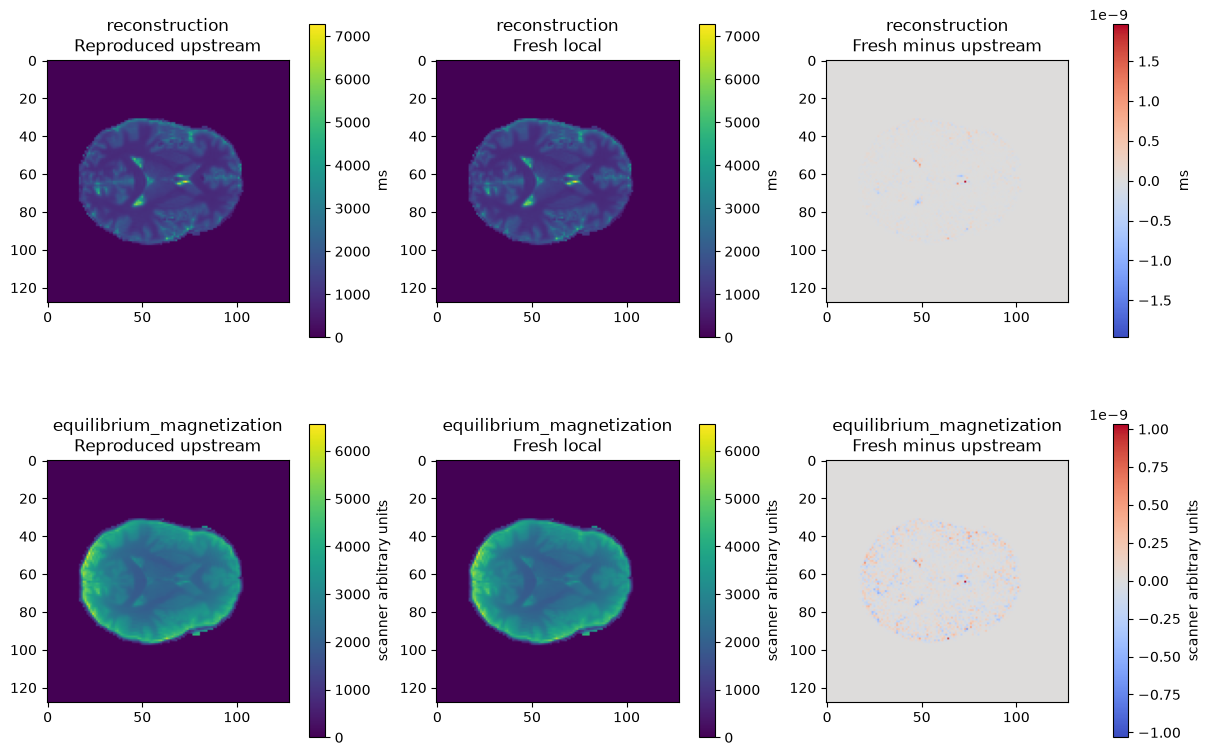

In [3]:
fig=comparison(fresh,reference)
plt.show()

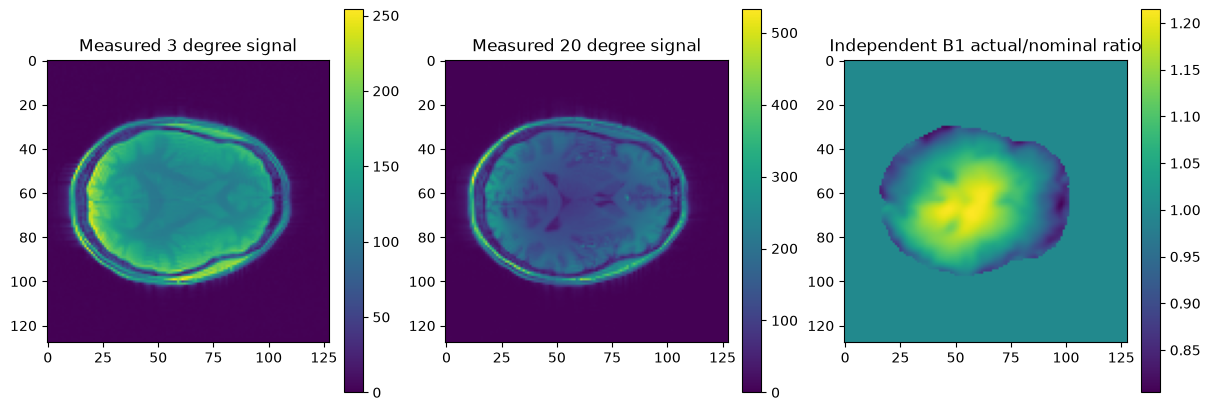

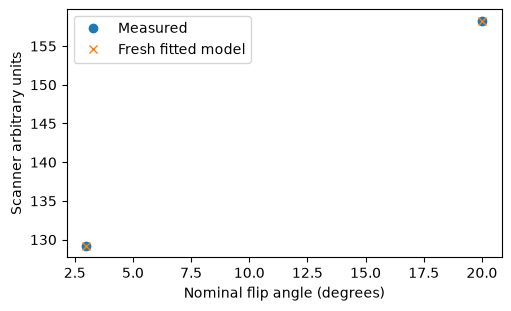

Two-angle fits interpolate measurements; this is not an independent accuracy estimate.


In [4]:
from src.preprocessing import load_data
from src.physics_model import spgr_signal
signal,b1,mask=load_data(ROOT/'data/raw_data.npz')
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,a,title in zip(axes,[signal[...,0],signal[...,1],b1],['Measured 3 degree signal','Measured 20 degree signal','Independent B1 actual/nominal ratio']):
 im=ax.imshow(a);ax.set_title(title);fig.colorbar(im,ax=ax)
plt.show()
idx=tuple(np.argwhere(mask)[len(np.argwhere(mask))//2])
pred=spgr_signal(fresh['equilibrium_magnetization'][0][idx],fresh['reconstruction'][0][idx],b1[idx])
fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
ax.plot([3,20],signal[idx],'o',label='Measured');ax.plot([3,20],pred,'x',label='Fresh fitted model')
ax.set(xlabel='Nominal flip angle (degrees)',ylabel='Scanner arbitrary units');ax.legend();plt.show()
print('Two-angle fits interpolate measurements; this is not an independent accuracy estimate.')


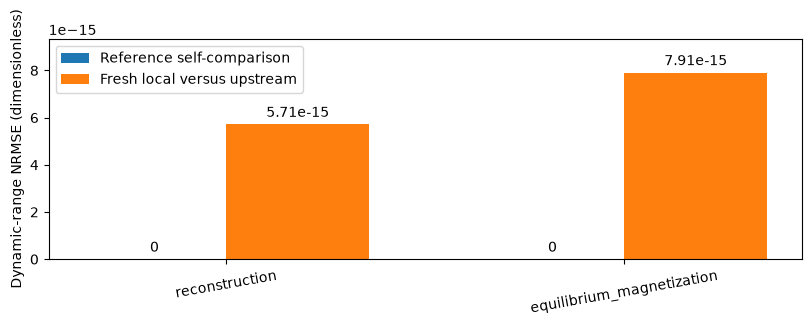

{
  "reconstruction": {
    "NCC": 1.0000000000000002,
    "dynamic_range_NRMSE": 5.7137273510922145e-15
  },
  "equilibrium_magnetization": {
    "NCC": 1.0000000000000002,
    "dynamic_range_NRMSE": 7.906641473030397e-15
  }
}


In [5]:
labels=list(fresh)
errors=[metrics(fresh[k],reference[k])[1] for k in labels]
fig,ax=plt.subplots(figsize=(8,3),layout='constrained')
x=np.arange(len(labels))
reference_bars=ax.bar(x-.18,[metrics(reference[k],reference[k])[1] for k in labels],.36,label='Reference self-comparison')
fresh_bars=ax.bar(x+.18,errors,.36,label='Fresh local versus upstream')
ax.margins(y=.18)
ax.bar_label(reference_bars,fmt='%.3g',padding=3)
ax.bar_label(fresh_bars,fmt='%.3g',padding=3)
ax.set_xticks(x,labels,rotation=10);ax.set_ylabel('Dynamic-range NRMSE (dimensionless)');ax.legend()
if all(error==0 for error in errors):
 ax.set_ylim(0,1e-6)
 ax.text(.5,.7,'Fresh and upstream arrays are bitwise equal; both plotted errors are 0.',ha='center',va='center',transform=ax.transAxes,wrap=True)
plt.show()
print(json.dumps({k:dict(zip(['NCC','dynamic_range_NRMSE'],metrics(fresh[k],reference[k]))) for k in labels},indent=2))

Fresh uncorrected versus reproduced upstream uncorrected: (0.9999999999999996, 6.145385204195604e-15)


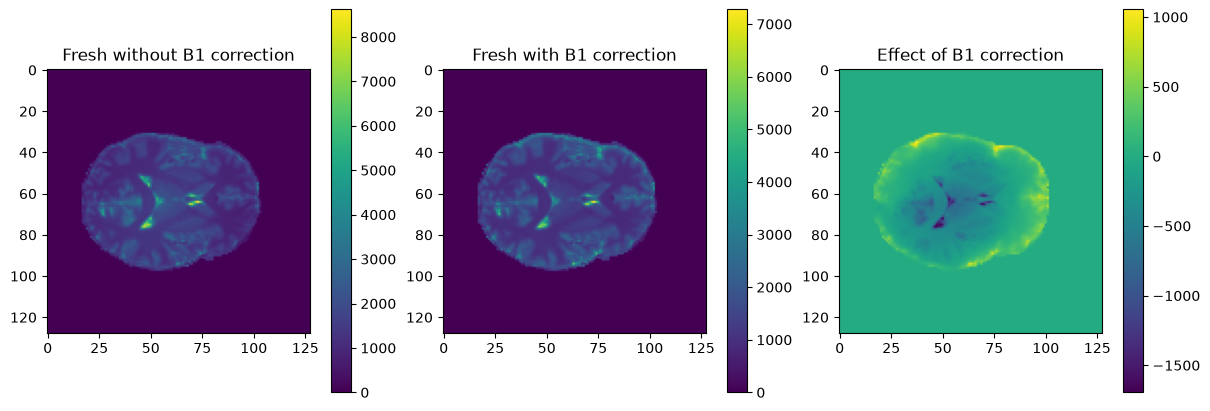

In [6]:
from src.solvers import reconstruct_uncorrected
uncorrected=reconstruct_uncorrected(ROOT/'data/raw_data.npz')
archived=np.load(ROOT/'notebooks/reference_outputs/upstream_uncorrected.npz')['reconstruction']
print('Fresh uncorrected versus reproduced upstream uncorrected:',metrics(uncorrected,archived))
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,a,label in zip(axes,[uncorrected[0],fresh['reconstruction'][0],fresh['reconstruction'][0]-uncorrected[0]],['Fresh without B1 correction','Fresh with B1 correction','Effect of B1 correction']):
 im=ax.imshow(a);ax.set_title(label);fig.colorbar(im,ax=ax)
plt.show()

## 6. Conclusion

The comparison isolates transmit-field sensitivity and supports direct-fit extraction. The reproduced maps are method references rather than in-vivo truth; two-angle noise, spoiling error and scanner scaling limit biological interpretation.

### Interpretation

The active calibrated and uncalibrated comparison isolates sensitivity to the independently measured transmit field. M0 remains in scanner units; neither map is an independent in-vivo physical truth measurement. Numerical reference agreement establishes extraction fidelity; it does not establish biological or clinical accuracy.
